# Modellvergleich: Logistische Regression vs. kNN (k = 25)

**Frage:** Welches der beiden Modelle sagt auf unbekannten Daten besser vorher, ob eine Person aktuell einen neuen Job sucht (`job_change = 1`)?

Alle Kennzahlen gelten für das **gemeinsame Testset** (3.832 Personen, 955 davon wechselwillig, also 24,9 %) und für den **Threshold 0,5**. Die kostenbasierten Thresholds aus den beiden Modell-Notebooks (LogReg: 0,885, kNN: 0,29) lassen wir hier bewusst weg, damit beide Modelle unter derselben Entscheidungsregel verglichen werden.

## Kurzvergleich vorab

| | Logistic Regression | kNN (k = 25) | Unterschied |
|---|---|---|---|
| Accuracy | 0,769 | 0,769 | praktisch gleich |
| Precision | 0,573 | 0,551 | praktisch gleich |
| **Recall** | 0,280 | **0,398** | **kNN findet 113 Wechselwillige mehr** |
| **F1** | 0,376 | **0,462** | **kNN besser** |
| **Specificity** | **0,931** | 0,892 | **LogReg hat 111 Fehlalarme weniger** |
| ROC AUC | 0,787 | 0,786 | praktisch gleich |

**Kernaussage:** Wie gut die Modelle Personen der Wahrscheinlichkeit nach ordnen, ist praktisch gleich: die AUC liegt bei 0,787 bzw. 0,786. Auch die Accuracy ist gleich, und beide liegen nur knapp 2 Prozentpunkte über der Baseline von 75,1 % („immer kein Wechsel“). Der Unterschied bei Threshold 0,5 ist ein **Tausch zwischen zwei Fehlerarten**: kNN markiert mehr Personen als wechselwillig und findet dadurch mehr echte Wechsler (höherer Recall und F1), erzeugt aber auch mehr Fehlalarme. Die LogReg ist vorsichtiger: Sie übersieht mehr Wechsler, irrt sich aber seltener bei Nicht-Wechslern. Welches Modell „besser“ ist, hängt also davon ab, welcher Fehler teurer ist. An der reinen Trennschärfe entscheidet es sich nicht.

## 1. Warum diese wenigen Daten für den Vergleich reichen

Aus den beiden Modell-Notebooks übernehmen wir pro Testperson nur drei Werte:

| Spalte | Bedeutung |
|---|---|
| `student_id` | eindeutige ID der Person, damit wir dieselben Personen zuordnen können |
| `y_true` | die echte Klasse (0 = sucht nicht, 1 = sucht) |
| `proba` | die vom **finalen** Modell geschätzte Wahrscheinlichkeit P(`job_change` = 1) |

**Das reicht, weil jede Bewertungskennzahl eines binären Klassifikators nur von zwei Dingen abhängt: der echten Klasse $y$ und der Ausgabe des Modells $\hat p$.** Wie das Modell intern zu $\hat p$ kommt (Koeffizienten, Nachbarn, Preprocessing), spielt für die Bewertung keine Rolle mehr. Konkret:

1. **Vorhersage bei Threshold 0,5:** $\hat y = 1$, wenn $\hat p \ge 0{,}5$, sonst $0$. Das ist genau die Regel, die `model.predict()` intern verwendet.
2. **Confusion Matrix:** Man zählt die vier Kombinationen aus $y$ und $\hat y$ (TN, FP, FN, TP).
3. **Accuracy, Precision, Recall, F1, Specificity:** Das sind Formeln aus diesen vier Zahlen, z. B. Recall = TP / (TP + FN).
4. **ROC-Kurve und AUC:** Man schiebt den Threshold von 1 bis 0 und berechnet für jeden Wert die False Positive Rate und die True Positive Rate. Dafür braucht man ebenfalls nur $y$ und $\hat p$. Die AUC hängt sogar nur von der **Reihenfolge** der $\hat p$ ab: Sie ist die Wahrscheinlichkeit, dass eine zufällige wechselwillige Person ein höheres $\hat p$ bekommt als eine zufällige nicht-wechselwillige.

Voraussetzung ist, dass die Wahrscheinlichkeiten wirklich das **Endergebnis** beider Modelle sind: Sie wurden einmal auf allen Trainingsdaten gelernt und dann auf das noch nicht benutzte Testset angewendet. Genau das passiert in beiden Notebooks (`model.predict_proba(X_test)` bzw. `final_model.predict_proba(X_test)`). Deshalb müssen wir keines der Modelle neu trainieren.

**Was mit diesen Daten nicht geht:** Fragen zum Modell selbst, z. B. welche Merkmale wichtig sind (Koeffizienten), Cross-Validation oder andere Hyperparameter. Dafür bleiben die Modell-Notebooks zuständig.

## 2. Steckbrief der beiden Modelle

| | Logistic Regression | kNN |
|---|---|---|
| Notebook | `logistic_regression_job_change.ipynb` | `knn_nach_vorlesung.ipynb` |
| Trainingsdaten | `customer_train_final_train.pkl` (15.326 Personen) | dieselben |
| Testdaten | `customer_train_final_test.pkl` (3.832 Personen) | dieselben |
| Eingabemerkmale | 10 (ohne `student_id`, `city`), nach Encoding 32 Spalten | dieselben 10, nach Encoding 32 Spalten |
| Encoding | ordinal: `education_level`, `experience`, `last_new_job`; One-Hot: die 4 nominalen Spalten | gleiche Aufteilung (ordinal per Kategorie-Code, nominal per `get_dummies`) |
| Skalierung | `StandardScaler` nur auf numerische und ordinale Merkmale | `StandardScaler` auf **alle** 32 Spalten |
| Hyperparameter | `C = 1` (Standard, nicht getunt), `max_iter = 2000` | **k = 25**, gewählt nach der höchsten Accuracy auf einem Validierungs-Split (76,7 %) und per 5-Fold-CV bestätigt (77,0 % ± 0,9) |
| Finales Training | auf allen 15.326 Trainingspersonen | auf allen 15.326 Trainingspersonen |
| Ausgabe `proba` | stetig (Sigmoid), 3.828 verschiedene Werte | Anteil wechselwilliger Personen unter den 25 Nachbarn, also nur Vielfache von 1/25 = 0,04 |
| **Threshold** | **0,5** | **0,5** (entspricht: mindestens 13 von 25 Nachbarn sind wechselwillig) |

## 3. Vergleichbarkeit

**Was gleich ist (und den Vergleich fair macht):**
- dieselben Trainingsdaten und dasselbe Testset; das prüfen wir unten über `student_id` und `y_true`
- dasselbe Testset wurde von keinem Modell zur Auswahl von k oder C benutzt
- dieselben 10 Eingabemerkmale
- derselbe Threshold 0,5 und dieselben Formeln für alle Kennzahlen; alles wird in diesem Notebook neu berechnet

**Kleine Unterschiede, die wir bewusst hinnehmen:**
- **Skalierung:** kNN skaliert auch die 0/1-Spalten, die LogReg nicht. Das gehört zum jeweiligen Verfahren: kNN rechnet mit Abständen und braucht vergleichbare Skalen, bei der LogReg ändert Skalierung der Dummies das Ergebnis kaum. Wir vergleichen also zwei **vollständige Pipelines**, jeweils so, wie sie für das Verfahren sinnvoll sind.
- **Tuning:** k wurde getunt, C nicht. Die LogReg hatte also keinen Vorteil durch Hyperparameter-Suche. Mit getuntem C könnte sie etwas besser abschneiden. Das ist unwahrscheinlich, weil die AUC schon gleich ist, aber möglich.
- **Grobe kNN-Wahrscheinlichkeiten:** kNN liefert nur 26 mögliche Werte. Deshalb besteht seine ROC-Kurve nur aus wenigen geraden Abschnitten. Die AUC bleibt trotzdem korrekt berechenbar und direkt vergleichbar.
- **Cross-Validation-Ergebnisse** aus den beiden Notebooks verwenden wir **nicht**: Die LogReg misst dort F1 mit StratifiedKFold, kNN misst Accuracy mit KFold. Diese Zahlen passen nicht zusammen.

**Fazit:** Es gibt keine grundsätzlichen Probleme bei der Vergleichbarkeit. Der Vergleich auf dem Testset bei Threshold 0,5 ist fair.

## 4. Setup und Daten laden

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

# ---- Feste Einstellungen aus den Modell-Notebooks ----
THRESHOLD = 0.5      # gemeinsamer Threshold für beide Modelle
K_KNN = 25           # gewähltes k im kNN-Notebook
C_LOGREG = 1         # Regularisierung der LogReg (Standardwert)

# ---- Einheitlicher Stil: LogReg immer blau, kNN immer orange ----
MODELS = ["Logistic Regression", f"kNN (k = {K_KNN})"]
COLORS = {MODELS[0]: "#2a78d6", MODELS[1]: "#eb6834"}
INK, INK2, GRID, GRAY = "#0b0b0b", "#52514e", "#e6e5e1", "#8a8883"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": INK,
    "axes.titlelocation": "left", "grid.color": GRID,
})

FIG_DIR = Path("figures_comparison")
FIG_DIR.mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()

In [2]:
DATA_DIR = Path("..") / "week 3"

lr  = pd.read_pickle(DATA_DIR / "pred_logreg.pkl")
knn = pd.read_pickle(DATA_DIR / "pred_knn.pkl")

# Über student_id zusammenführen, damit garantiert dieselben Personen verglichen werden
df = lr.merge(knn, on="student_id", suffixes=("_lr", "_knn"), validate="one_to_one")

# ---- Prüfungen der Vergleichbarkeit ----
assert len(df) == len(lr) == len(knn), "Nicht alle Testpersonen kommen in beiden Dateien vor."
assert (df["y_true_lr"] == df["y_true_knn"]).all(), "Die echten Labels stimmen nicht überein."
assert df.isna().sum().sum() == 0, "Es gibt fehlende Werte."
assert df[["proba_lr", "proba_knn"]].stack().between(0, 1).all()
# kNN-Wahrscheinlichkeiten müssen Vielfache von 1/k sein -> bestätigt k = 25
assert np.allclose(df["proba_knn"] * K_KNN, np.round(df["proba_knn"] * K_KNN)), "kNN-Ausgabe passt nicht zu k = 25."

y = df["y_true_lr"].to_numpy()
proba = {MODELS[0]: df["proba_lr"].to_numpy(), MODELS[1]: df["proba_knn"].to_numpy()}
pred  = {m: (p >= THRESHOLD).astype(int) for m, p in proba.items()}

baseline_acc = 1 - y.mean()   # Accuracy der Regel "immer kein Wechsel" auf dem Testset

print(f"Testpersonen: {len(y):,} | davon wechselwillig: {y.sum():,} ({y.mean():.1%})")
print(f"Baseline-Accuracy (immer 'kein Wechsel'): {baseline_acc:.3f}")
print(f"Verschiedene proba-Werte  LogReg: {df['proba_lr'].nunique():,} | kNN: {df['proba_knn'].nunique()}")

Testpersonen: 3,832 | davon wechselwillig: 955 (24.9%)
Baseline-Accuracy (immer 'kein Wechsel'): 0.751
Verschiedene proba-Werte  LogReg: 3,828 | kNN: 24


**Ergebnis:** Alle Prüfungen sind bestanden. Beide Dateien enthalten genau dieselben 3.832 Testpersonen mit identischen Labels. Die kNN-Wahrscheinlichkeiten sind alle Vielfache von 0,04, das bestätigt k = 25.

## 5. Kennzahlen berechnen

Alle Kennzahlen werden hier aus `y_true` und `proba` neu berechnet. Sie stimmen mit den Werten in den Modell-Notebooks überein (LogReg: TN 2.678 / FP 199 / FN 688 / TP 267; kNN: TN 2.567 / FP 310 / FN 575 / TP 380).

| Kennzahl | Formel | Frage dahinter |
|---|---|---|
| Accuracy | (TP + TN) / alle | Wie viele Vorhersagen sind richtig? |
| Precision | TP / (TP + FP) | Wie viele der als wechselwillig markierten Personen sind es wirklich? |
| Recall | TP / (TP + FN) | Wie viele der Wechselwilligen findet das Modell? |
| F1 | 2 · P · R / (P + R) | Kompromiss aus Precision und Recall |
| Specificity | TN / (TN + FP) | Wie viele der Nicht-Wechselwilligen werden richtig erkannt? |
| ROC AUC | Fläche unter der ROC-Kurve | Wie gut trennt das Modell, **unabhängig vom Threshold**? |

In [3]:
rows = []
for m in MODELS:
    tn, fp, fn, tp = confusion_matrix(y, pred[m], labels=[0, 1]).ravel()
    rows.append({
        "Model": m, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": accuracy_score(y, pred[m]),
        "Precision": precision_score(y, pred[m], zero_division=0),
        "Recall": recall_score(y, pred[m]),
        "F1": f1_score(y, pred[m]),
        "Specificity": tn / (tn + fp),
        "ROC AUC": roc_auc_score(y, proba[m]),
    })
results = pd.DataFrame(rows).set_index("Model")
METRICS = ["Accuracy", "Precision", "Recall", "F1", "Specificity", "ROC AUC"]

display(results[["TN", "FP", "FN", "TP"]])
diff = (results.loc[MODELS[0], METRICS] - results.loc[MODELS[1], METRICS]).rename("LogReg − kNN")
display(pd.concat([results[METRICS].T, diff], axis=1).round(3))

,TN,FP,FN,TP
Model,,,,
Logistic Regression,2678,199,688,267
kNN (k = 25),2567,310,575,380


,Logistic Regression,kNN (k = 25),LogReg − kNN
Accuracy,0.769,0.769,-0.001
Precision,0.573,0.551,0.022
Recall,0.280,0.398,-0.118
F1,0.376,0.462,-0.086
Specificity,0.931,0.892,0.039
ROC AUC,0.787,0.786,0.001


## 6. Grafik 1 – Treffer und Fehler pro echter Klasse

Die Confusion Matrix wird hier als **100 %-Balken pro echter Klasse** dargestellt. Jeder Balken steht für eine Gruppe von Personen mit derselben echten Klasse und zeigt, welcher Anteil davon richtig bzw. falsch vorhergesagt wurde:

- **Obere zwei Balken – Personen, die wirklich einen Job suchen (955):** Der dunkle Teil ist der Anteil der **gefundenen** Wechselwilligen (TP, entspricht dem Recall), der helle Teil der Anteil der **übersehenen** (FN).
- **Untere zwei Balken – Personen, die keinen Job suchen (2.877):** Der dunkle Teil ist der Anteil der **richtig erkannten** Nicht-Wechselwilligen (TN, entspricht der Specificity), der helle Teil die **Fehlalarme** (FP).

Diese Darstellung ist bei unserer ungleichen Klassenverteilung lesbarer als die klassische Matrix: Bei absoluten Zahlen dominieren die 2.877 Nicht-Wechselwilligen das Bild.

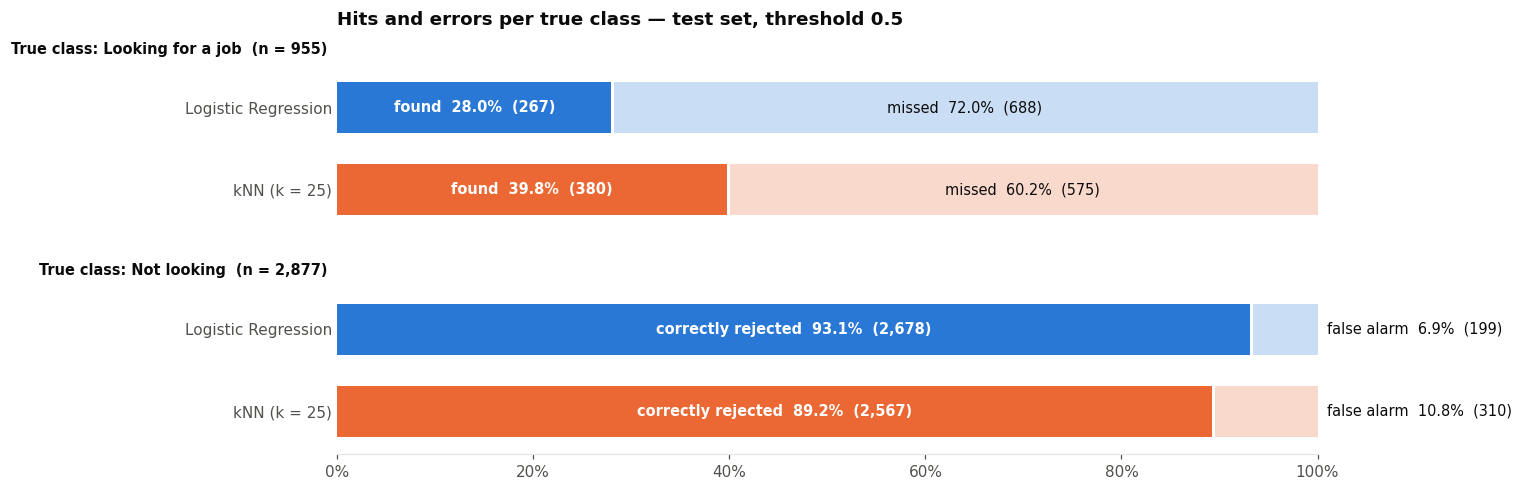

In [4]:
groups = [
    ("Looking for a job", 1, "found", "missed"),
    ("Not looking", 0, "correctly rejected", "false alarm"),
]
fig, ax = plt.subplots(figsize=(11.5, 4.6))
ypos, yticks, ylabels = 0, [], []

for title, cls, good_lbl, bad_lbl in groups:
    n_cls = int((y == cls).sum())
    for m in MODELS:
        mask = y == cls
        correct = int((pred[m][mask] == cls).sum())
        wrong = n_cls - correct
        share = correct / n_cls
        col = COLORS[m]
        ax.barh(ypos, share, color=col, height=0.62)
        ax.barh(ypos, 1 - share, left=share + 0.003, color=col, alpha=0.25, height=0.62)
        ax.text(share / 2, ypos, f"{good_lbl}  {share:.1%}  ({correct:,})",
                ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
        if 1 - share >= 0.25:   # breites Segment: Text in den Balken
            ax.text(share + (1 - share) / 2, ypos, f"{bad_lbl}  {1-share:.1%}  ({wrong:,})",
                    ha="center", va="center", color=INK, fontsize=9.5)
        else:                   # schmales Segment: Text rechts neben den Balken
            ax.text(1.01, ypos, f"{bad_lbl}  {1-share:.1%}  ({wrong:,})",
                    ha="left", va="center", color=INK, fontsize=9.5)
        yticks.append(ypos); ylabels.append(m)
        ypos += 1
    ax.text(-0.01, ypos - 2.62, f"True class: {title}  (n = {n_cls:,})", transform=ax.get_yaxis_transform(),
            ha="right", va="bottom", fontsize=9.5, fontweight="bold", color=INK)
    ypos += 0.7

ax.set_yticks(yticks, ylabels)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xticks(np.linspace(0, 1, 6))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Hits and errors per true class — test set, threshold {THRESHOLD}", pad=26)
save_figure(fig, "01_hits_and_errors_per_class.png")

**So liest du die Grafik:** Für jede echte Klasse stehen die beiden Modelle direkt untereinander. Je länger der dunkle Teil, desto besser ist das Modell bei dieser Gruppe.

**Vergleich:**
- **Wechselwillige (oben):** kNN findet **39,8 %** (380 von 955), die LogReg nur **28,0 %** (267). kNN erkennt also **113 Wechselwillige mehr**. Trotzdem übersehen beide Modelle die Mehrheit der Wechselwilligen (60 % bzw. 72 %).
- **Nicht-Wechselwillige (unten):** Die LogReg erkennt **93,1 %** richtig (2.678 von 2.877), kNN **89,2 %** (2.567). kNN erzeugt **111 Fehlalarme mehr** (310 statt 199).
- Die beiden Unterschiede sind fast gleich groß, gehen aber in entgegengesetzte Richtung. Insgesamt sind deshalb fast gleich viele Vorhersagen richtig: 2.945 bei der LogReg, 2.947 bei kNN.

**Key Takeaways:**
- Bei Threshold 0,5 **tauschen** die Modelle Fehlerarten: kNN findet mehr Wechselwillige und bezahlt das mit mehr Fehlalarmen. Die LogReg ist vorsichtiger.
- Beide Modelle sind bei der kleineren Klasse schwach: Bei 0,5 übersieht sogar das bessere Modell 6 von 10 Wechselwilligen. Das liegt auch an der Klassenverteilung (nur 25 % Wechselwillige), weshalb wenige Personen eine Wahrscheinlichkeit über 0,5 bekommen.
- Ist das Ziel, möglichst viele Wechselwillige zu **finden**, ist kNN bei 0,5 klar im Vorteil.

## 7. Grafik 2 – Kennzahlen im Überblick (gruppierte Balken)

Alle sechs Kennzahlen nebeneinander, links die LogReg (blau), rechts kNN (orange). Die gestrichelte Linie über der Accuracy zeigt die **Baseline von 75,1 %**: so oft liegt die Regel „immer kein Wechsel“ richtig. Die ROC AUC steht durch eine Lücke abgesetzt am Ende, weil sie als einzige Kennzahl **nicht vom Threshold abhängt**.

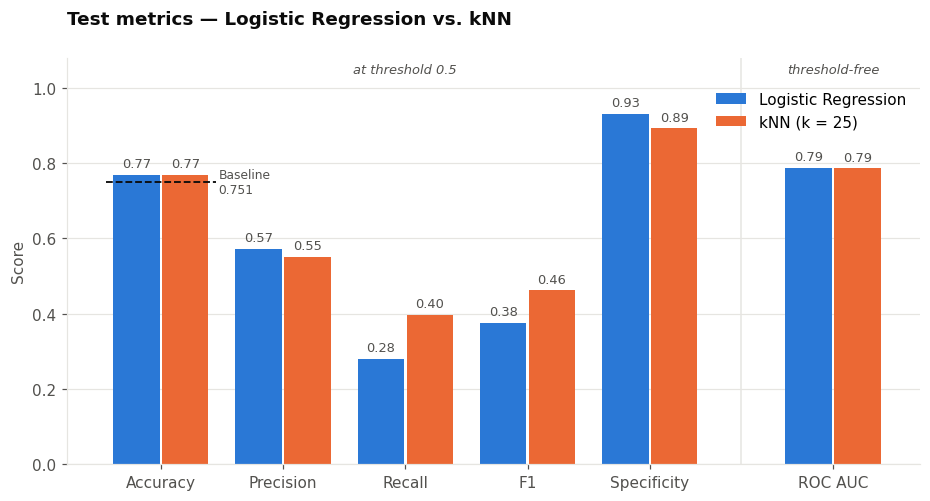

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(METRICS)).astype(float)
x[-1] += 0.5                      # ROC AUC optisch absetzen
w = 0.38

for i, m in enumerate(MODELS):
    vals = results.loc[m, METRICS].to_numpy(dtype=float)
    offset = (-1 if i == 0 else 1) * (w / 2 + 0.01)
    bars = ax.bar(x + offset, vals, w, color=COLORS[m], label=m)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], padding=3, fontsize=8.5, color=INK2)

# Baseline nur über der Accuracy-Gruppe
ax.hlines(baseline_acc, x[0] - 0.45, x[0] + 0.45, color=INK, ls="--", lw=1.2)
ax.annotate(f"Baseline\n{baseline_acc:.3f}", (x[0] + 0.47, baseline_acc), va="center", fontsize=8, color=INK2)

ax.axvline((x[-2] + x[-1]) / 2, color=GRID, lw=1)
ax.text(x[-1], 1.04, "threshold-free", ha="center", fontsize=8.5, color=INK2, style="italic")
ax.text((x[0] + x[-2]) / 2, 1.04, f"at threshold {THRESHOLD}", ha="center", fontsize=8.5, color=INK2, style="italic")

ax.set_xticks(x, METRICS)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.95))
ax.set_title("Test metrics — Logistic Regression vs. kNN", pad=22)
save_figure(fig, "02a_metrics_grouped_bars.png")

**So liest du die Grafik:** Je höher der Balken, desto besser. Bei jeder Kennzahl stehen beide Modelle direkt nebeneinander.

**Vergleich:**
- **Accuracy (0,769 vs. 0,769):** gleich. Beide liegen nur rund **1,8 Prozentpunkte über der Baseline**. Die Accuracy allein zeigt also kaum, dass die Modelle etwas gelernt haben, weil sie von der großen Klasse „kein Wechsel“ dominiert wird.
- **Precision (0,57 vs. 0,55):** fast gleich. Wenn ein Modell jemanden als wechselwillig markiert, stimmt das bei beiden in gut der Hälfte der Fälle.
- **Recall (0,28 vs. 0,40) und F1 (0,38 vs. 0,46):** Hier ist kNN deutlich besser. Das sind die Kennzahlen, die sich auf das Finden der Wechselwilligen konzentrieren.
- **Specificity (0,93 vs. 0,89):** Hier ist die LogReg besser, das ist die Kehrseite des niedrigeren Recalls.
- **ROC AUC (0,787 vs. 0,786):** gleich. Über alle möglichen Thresholds hinweg trennen beide Modelle gleich gut.

**Key Takeaways:**
- Auf den Gesamtkennzahlen (Accuracy, AUC) gibt es **keinen Gewinner**.
- Die Unterschiede entstehen erst durch den festen Threshold 0,5. kNN vergibt häufiger Wahrscheinlichkeiten ≥ 0,5: Es markiert 690 Personen als wechselwillig, die LogReg nur 466.
- Für die Bewertung bei ungleichen Klassen sind **Recall, Precision und F1** aussagekräftiger als die Accuracy.

## 8. Grafik 3 – Dumbbell-Chart: Wie groß ist der Abstand?

Die Balkengrafik zeigt die absoluten Werte, der Dumbbell-Chart dagegen den **Abstand**. Pro Kennzahl gibt es zwei Punkte auf derselben Linie, die Länge des grauen Balkens zwischen ihnen ist der Unterschied. Rechts steht, welches Modell um wie viel vorne liegt.

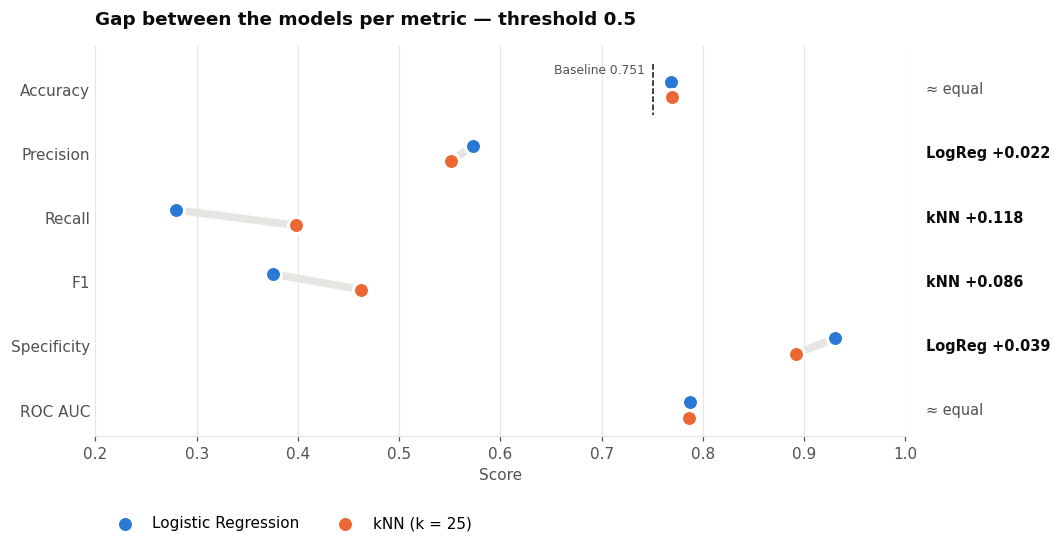

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
vals_lr  = results.loc[MODELS[0], METRICS].to_numpy(dtype=float)
vals_knn = results.loc[MODELS[1], METRICS].to_numpy(dtype=float)
ypos = np.arange(len(METRICS))

for i in ypos:
    ax.plot([vals_lr[i], vals_knn[i]], [i - 0.12, i + 0.12], color=GRID, lw=5, solid_capstyle="round", zorder=1)
# kleiner vertikaler Versatz, damit sich gleiche Werte nicht verdecken
for m, vals, off in [(MODELS[0], vals_lr, -0.12), (MODELS[1], vals_knn, 0.12)]:
    ax.scatter(vals, ypos + off, s=110, color=COLORS[m], edgecolor="white", linewidth=2, zorder=3, label=m)

for i, metric in enumerate(METRICS):
    d = vals_lr[i] - vals_knn[i]
    if abs(d) < 0.01:
        txt, col = "≈ equal", INK2
    else:
        winner = "LogReg" if d > 0 else "kNN"
        txt, col = f"{winner} +{abs(d):.3f}", INK
    ax.text(1.02, i, txt, va="center", fontsize=9.5, color=col,
            fontweight="bold" if abs(d) >= 0.01 else "normal")

ax.vlines(baseline_acc, -0.4, 0.4, color=INK, ls="--", lw=1)
ax.text(baseline_acc - 0.008, -0.3, f"Baseline {baseline_acc:.3f}", ha="right", va="center", fontsize=8, color=INK2)

ax.set_yticks(ypos, METRICS)
ax.invert_yaxis()
ax.set_xlim(0.2, 1.0)
ax.set_xlabel("Score")
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower left", ncol=2, bbox_to_anchor=(0, -0.28))
ax.set_title(f"Gap between the models per metric — threshold {THRESHOLD}", pad=14)
save_figure(fig, "02b_metrics_dumbbell.png")

**So liest du die Grafik:** Blau (LogReg) steht jeweils leicht oberhalb, Orange (kNN) leicht unterhalb der Zeile, damit sich gleiche Werte nicht verdecken. Liegen die Punkte senkrecht übereinander, sind die Modelle gleich gut. Je länger der graue Balken, desto größer der Unterschied. Die x-Achse beginnt bei 0,2, damit die Abstände sichtbar werden.

**Vergleich:**
- **Drei Kennzahlen mit deutlichem Abstand:** Recall (**kNN +0,118**), F1 (**kNN +0,086**) und Specificity (**LogReg +0,039**).
- **Drei Kennzahlen ohne nennenswerten Abstand:** Accuracy, ROC AUC (jeweils unter 0,01) und Precision (LogReg +0,022). Den Unterschied bei der Precision sollte man nicht überbewerten: Er beruht nur auf 466 bzw. 690 markierten Personen.
- Der größte Abstand liegt beim Recall. Dort unterscheiden sich die Modelle am stärksten.

**Key Takeaways:**
- Der Abstand bei Recall (kNN) ist etwa **dreimal so groß** wie der bei Specificity (LogReg). In Prozent sieht der Tausch also günstig für kNN aus. In absoluten Zahlen ist er ausgeglichen: +113 gefundene Wechselwillige stehen +111 Fehlalarmen gegenüber, weil es dreimal so viele Nicht-Wechselwillige gibt.
- Bei den Gesamtkennzahlen liegen die Punkte praktisch aufeinander. Die Modelle unterscheiden sich in der **Fehlerverteilung**, nicht in der Gesamtqualität.

## 9. Grafik 4 – Radar-Chart: das Profil der Modelle

Der Radar-Chart legt alle sechs Kennzahlen auf Achsen im Kreis. Jedes Modell bildet eine Fläche, deren Form sein **Stärken-Schwächen-Profil** zeigt. Außen ist besser (Skala 0 bis 1).

*Hinweis:* Radar-Charts eignen sich gut, um Profile auf einen Blick zu vergleichen. Exakte Werte liest man besser in den Grafiken 2 und 3 ab. Die Größe der Fläche hängt außerdem von der Reihenfolge der Achsen ab und ist **kein** Gesamtmaß.

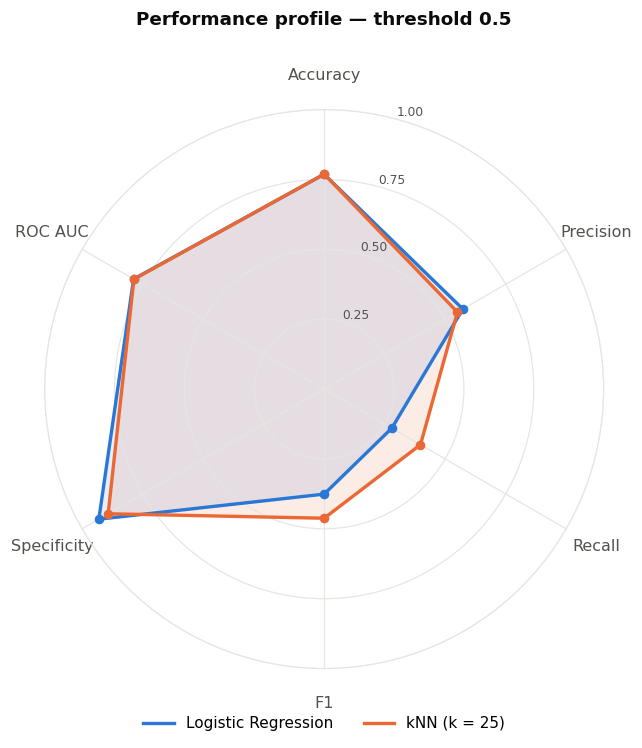

In [7]:
angles = np.linspace(0, 2 * np.pi, len(METRICS), endpoint=False)
angles_closed = np.append(angles, angles[0])

fig, ax = plt.subplots(figsize=(6.6, 6.6), subplot_kw={"polar": True})
ax.set_theta_offset(np.pi / 2)    # erste Achse oben
ax.set_theta_direction(-1)        # im Uhrzeigersinn

for m in MODELS:
    vals = results.loc[m, METRICS].to_numpy(dtype=float)
    v = np.append(vals, vals[0])
    ax.plot(angles_closed, v, color=COLORS[m], lw=2.2, label=m)
    ax.fill(angles_closed, v, color=COLORS[m], alpha=0.12)
    ax.scatter(angles, vals, color=COLORS[m], s=28, zorder=3)

ax.set_xticks(angles, METRICS, fontsize=10.5)
ax.tick_params(axis="x", pad=12)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0], ["0.25", "0.50", "0.75", "1.00"], fontsize=8, color=INK2)
ax.set_rlabel_position(90 / len(METRICS))
ax.spines["polar"].set_color(GRID)
ax.grid(color=GRID)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2)
ax.set_title(f"Performance profile — threshold {THRESHOLD}", pad=28, loc="center")
save_figure(fig, "02c_metrics_radar.png")

**So liest du die Grafik:** Wo eine Linie weiter außen liegt, ist das Modell bei dieser Kennzahl besser. Wo sich die Linien decken, sind beide gleich.

**Vergleich:**
- Die Flächen **decken sich fast überall**: bei Accuracy, ROC AUC und Precision.
- **kNN beult nach außen** bei Recall und F1. Das ist die Seite „Wechselwillige finden“.
- **Die LogReg liegt leicht außen** bei Specificity. Das ist die Seite „Nicht-Wechselwillige richtig ablehnen“.
- Beide Modelle haben dieselbe Grundform: Specificity, Accuracy und AUC sind hoch, Recall und F1 klar niedriger. Das typische Muster bei einer seltenen Zielklasse.

**Key Takeaways:**
- Die Profile sind **sehr ähnlich**. Kein Modell ist auf allen Achsen besser.
- Die Schwachstelle beider Modelle ist dieselbe: der **Recall**, also das Finden der Wechselwilligen.

## 10. Grafik 5 – ROC-Kurven beider Modelle

Die ROC-Kurve zeigt für **alle möglichen Thresholds**, wie viele Wechselwillige gefunden werden (True Positive Rate = Recall, y-Achse) und wie viele Nicht-Wechselwillige dabei fälschlich markiert werden (False Positive Rate = 1 − Specificity, x-Achse). Ein Threshold von 1 liegt unten links (niemand wird markiert), ein Threshold von 0 oben rechts (alle werden markiert). Die Diagonale entspricht reinem Raten (AUC 0,5).

Diese Grafik ist der einzige Teil des Vergleichs, der **nicht** auf den Threshold 0,5 festgelegt ist. Sie zeigt, wie gut die Modelle grundsätzlich trennen.

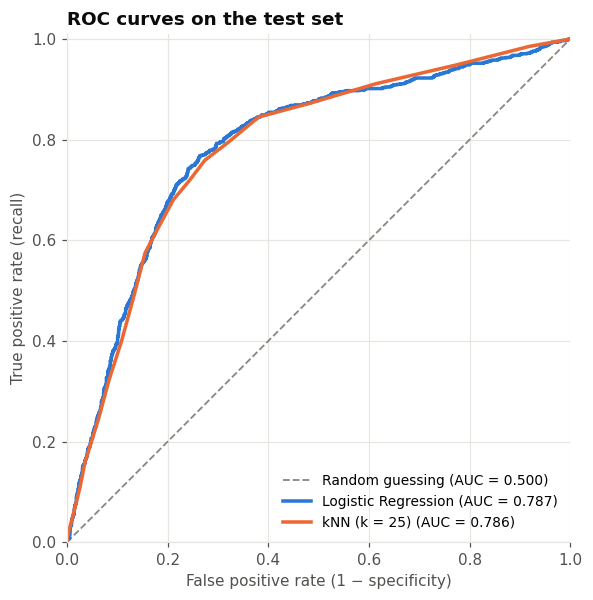

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 6.0))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1.2, label="Random guessing (AUC = 0.500)")

for m in MODELS:
    fpr, tpr, _ = roc_curve(y, proba[m])
    auc_val = results.loc[m, "ROC AUC"]
    ax.plot(fpr, tpr, color=COLORS[m], lw=2.3, label=f"{m} (AUC = {auc_val:.3f})")

ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_aspect("equal")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.grid(True); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set_title("ROC curves on the test set")
save_figure(fig, "03a_roc_curves.png")

**So liest du die Grafik:** Je weiter eine Kurve nach **oben links** reicht, desto besser trennt das Modell: Es findet viele Wechselwillige bei wenigen Fehlalarmen. Die AUC ist die Fläche unter der Kurve (1 wäre perfekt, 0,5 ist Raten).

**Vergleich:**
- Die beiden Kurven **liegen fast aufeinander**. Die AUC ist mit **0,787** (LogReg) und **0,786** (kNN) praktisch identisch.
- Die **kNN-Kurve ist eckig**: Sie besteht aus wenigen geraden Abschnitten, weil kNN mit k = 25 nur Vielfache von 0,04 ausgibt (im Testset kommen 24 verschiedene Werte vor). Jede Ecke entspricht einem möglichen Threshold (z. B. 12/25 = 0,48 oder 13/25 = 0,52). Die LogReg liefert fast für jede Person einen eigenen Wert und deshalb eine feine, glatte Kurve.
- Im Bereich niedriger bis mittlerer False Positive Rate (etwa 0,05 bis 0,4) liegt die LogReg minimal über kNN, bei hoher False Positive Rate (ab etwa 0,6) liegt kNN minimal vorne. Die Abstände sind überall sehr klein. Einen Bereich, in dem ein Modell klar besser ist, gibt es nicht.
- Beide liegen deutlich über der Diagonalen, haben also echtes Signal gelernt. Mit einer AUC von etwa 0,79 ist die Trennung aber nur **mittelmäßig**.

**Key Takeaways:**
- Unabhängig vom Threshold sind beide Modelle **gleich gut**. Die Unterschiede bei Recall, F1 und Specificity aus den Grafiken 1 bis 4 entstehen dadurch, **an welcher Stelle der Kurve** der Threshold 0,5 jeweils liegt: bei kNN weiter oben rechts (mehr markiert), bei der LogReg weiter unten links (weniger markiert).
- Daraus folgt: Mit einem angepassten Threshold könnte die LogReg ungefähr den Recall von kNN erreichen, und umgekehrt. Bei Threshold 0,5 ist das aber nicht der Fall.

## 11. Sind die Unterschiede mehr als Zufall? (Bootstrap)

Ein Testset mit 3.832 Personen ist nur eine Stichprobe. Um abzuschätzen, ob ein Unterschied nur Zufall sein könnte, ziehen wir 2.000-mal eine neue Stichprobe gleicher Größe aus dem Testset, mit Zurücklegen (**Bootstrap**). Für jede Stichprobe berechnen wir den Unterschied LogReg − kNN. Beide Modelle werden immer auf **denselben** gezogenen Personen bewertet. Das 95 %-Intervall gibt an, in welchem Bereich der Unterschied mit hoher Wahrscheinlichkeit liegt. **Enthält das Intervall die 0, ist der Unterschied nicht gesichert.**

In [9]:
def metric_vector(y_true, p_lr, p_knn):
    out = []
    for p in (p_lr, p_knn):
        yhat = (p >= THRESHOLD).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, yhat, labels=[0, 1]).ravel()
        out.append([(tp + tn) / len(y_true), tp / max(tp + fp, 1), tp / (tp + fn),
                    2 * tp / (2 * tp + fp + fn), tn / (tn + fp), roc_auc_score(y_true, p)])
    return np.array(out[0]) - np.array(out[1])

rng = np.random.default_rng(42)
p_lr, p_knn = proba[MODELS[0]], proba[MODELS[1]]
boot = np.array([metric_vector(y[idx], p_lr[idx], p_knn[idx])
                 for idx in (rng.integers(0, len(y), len(y)) for _ in range(2000))])

lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
boot_table = pd.DataFrame({
    "LogReg − kNN": diff[METRICS].to_numpy(dtype=float),
    "95% CI lower": lo, "95% CI upper": hi,
}, index=METRICS)
boot_table["Significant?"] = np.where((lo > 0) | (hi < 0), "yes", "no")
display(boot_table.round(3))

,LogReg − kNN,95% CI lower,95% CI upper,Significant?
Accuracy,-0.001,-0.012,0.011,no
Precision,0.022,-0.016,0.061,no
Recall,-0.118,-0.153,-0.082,yes
F1,-0.086,-0.122,-0.049,yes
Specificity,0.039,0.028,0.049,yes
ROC AUC,0.001,-0.009,0.012,no


**Ergebnis:**
- **Gesichert:** Recall (kNN besser, Intervall etwa −0,15 bis −0,08), F1 (kNN besser) und Specificity (LogReg besser, etwa +0,03 bis +0,05).
- **Nicht gesichert:** Accuracy, Precision und ROC AUC. Ihre Intervalle schließen die 0 ein.

Das bestätigt die Grafiken: Die Modelle unterscheiden sich nachweisbar in der **Fehlerverteilung bei 0,5**, aber nicht in der **Gesamtgüte**.

## 12. Gesamtfazit

1. **Faire Grundlage:** Beide Modelle wurden auf denselben Daten trainiert und auf demselben, vorher unbenutzten Testset mit demselben Threshold 0,5 bewertet. Die Prüfungen in Abschnitt 4 bestätigen das.
2. **Gleiche Gesamtgüte:** Accuracy (0,769 vs. 0,769) und ROC AUC (0,787 vs. 0,786) sind praktisch identisch. Beide liegen nur knapp über der Baseline von 75,1 %. Bei einer AUC von etwa 0,79 ist die Trennung mittelmäßig.
3. **Unterschied bei Threshold 0,5:** kNN findet nachweisbar mehr Wechselwillige (Recall 0,40 vs. 0,28, F1 0,46 vs. 0,38). Die LogReg macht nachweisbar weniger Fehlalarme (Specificity 0,93 vs. 0,89). In absoluten Zahlen: +113 gefundene Wechsler gegen +111 zusätzliche Fehlalarme.
4. **Empfehlung:** Wenn bei Threshold 0,5 das **Finden wechselwilliger Personen** im Vordergrund steht, was bei dieser Aufgabe naheliegt, ist **kNN (k = 25) das bessere Modell**. Wenn Fehlalarme teuer sind, ist die LogReg vorzuziehen. Grundsätzlich ist keines der beiden Modelle überlegen. Die Wahl des Thresholds beeinflusst das Ergebnis stärker als die Wahl des Modells.
5. **Einschränkungen:** C der LogReg wurde nicht getunt. Die kostenbasierten Thresholds aus den Modell-Notebooks wurden hier bewusst nicht verglichen.